Dataset shape: (569, 30)
Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
benign       357
malignant    212
Name: count, dtype: int64
Baseline Logistic Regression
Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



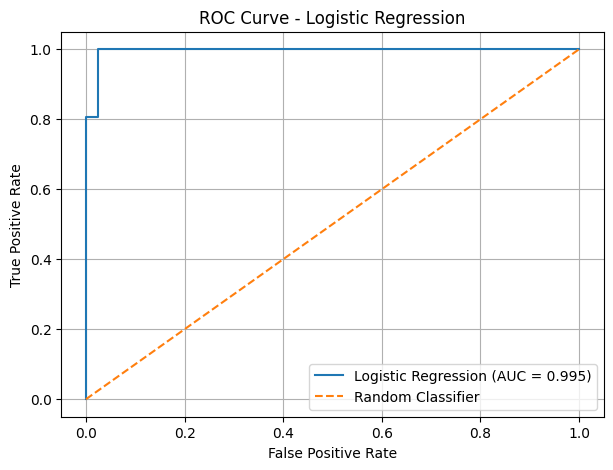

ROC-AUC Score: 0.995

Balanced Logistic Regression
Confusion Matrix:
[[41  1]
 [ 4 68]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Decision Tree Classifier
Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


Model Comparison:
                       Model  Accuracy  Precision (Malignant)  Recall (Malignant)  F1 (Malignant)  ROC-AUC (Benign)
         Log

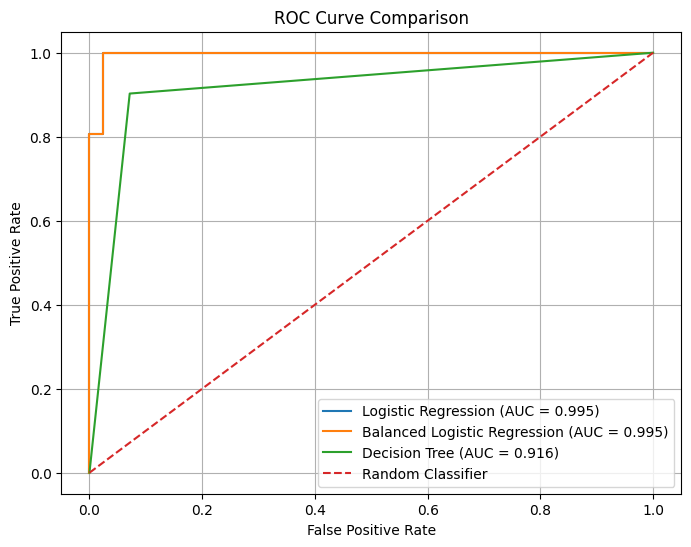

In [ ]:

# Step 1: Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Step 2: Load Dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", dict(enumerate(data.target_names)))
print("\nClass distribution:")
print(pd.Series(y).map({0: "malignant", 1: "benign"}).value_counts())

# Step 3: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Train Baseline Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Step 6: Confusion Matrix and Classification Report
print("Baseline Logistic Regression")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=data.target_names
))

# Step 7: ROC Curve and AUC Score
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(auc, 3))

# Step 8: Handle Class Imbalance
model_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = model_balanced.predict(X_test_scaled)
y_prob_balanced = model_balanced.predict_proba(X_test_scaled)[:, 1]

print("\nBalanced Logistic Regression")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_balanced,
    target_names=data.target_names
))

# Step 9: Compare with Decision Tree Classifier
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)
y_prob_tree = tree.predict_proba(X_test)[:, 1]

print("\nDecision Tree Classifier")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_tree,
    target_names=data.target_names
))

# Step 10: Compare Model Performance
models = {
    "Logistic Regression": (y_pred, y_prob),
    "Balanced Logistic Regression": (y_pred_balanced, y_prob_balanced),
    "Decision Tree": (y_pred_tree, y_prob_tree)
}

results = []

for name, (predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Malignant)": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Recall (Malignant)": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "F1 (Malignant)": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "ROC-AUC (Benign)": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df.round(3).to_string(index=False))

# Step 11: Compare ROC Curves
plt.figure(figsize=(8, 6))

for name, (predictions, probabilities) in models.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()
